# Choosing which Census counts to add up

A Census query like "males aged 5 to 9" can usually be answered from several of the
released noisy measurements, and each route has a different price.  Using a count
that is too coarse counts people you did not ask about (*coverage* error), while
adding many fine counts piles up independent noise (*noise* variance).  This notebook
searches for the best trade-off with the Pareto evolutionary algorithm in
`noisyvalue.dataset.evolve`, over a problem built by `noisyvalue.dataset.cover`, and
then turns the winning selection into a posterior with `noisyvalue`.

The steps:

1. State the query the way the published table does (`dhc_table_variables`, table P12).
2. Build a `CoverProblem`: every candidate count, the base cells it covers, its noise variance.
3. Run the Pareto EA with `cover.noise_objective` and `cover.coverage_objective`.
4. Take the zero-coverage, lowest-noise solution, pull those cells' noisy values out of a
   `View`, add them (or subtract, for signed genomes) and sample the result.

Requires the Vermont county DHC partitions: `fetch_dhc("county", state="VT")`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from noisyvalue.census import dhc_2020, dhc_table_variables
from noisyvalue.dataset import cover
from noisyvalue.dataset.evolve import pareto_evolutionary_algorithm
from noisyvalue.sample import sample_noisy_values

## 1. The query and the view

We use Chittenden County, Vermont (state `50`, county `007`).  A `View` resolves every
cell once and shares it, so everything we pull from it stays jointly consistent.
Table P12 cell `P12_004N` is "Male: 5 to 9 years".

In [2]:
view = dhc_2020.view("county", state="50", county="007")

entry = dhc_table_variables()["P12_004N"]
filters = {k: v for k, v in entry.items() if k not in ("query", "label")}
print(entry["label"], "-", filters)

query = cover.levels_for(dhc_2020, entry["query"], filters)
query

Male: 5 to 9 years - {'sex': ('male',), 'age': ('5', '6', '7', '8', '9')}


{'sex': ('male',), 'age': ('5', '6', '7', '8', '9')}

## 2. The cover problem

The catalog carries no variances, so we read one per measurement from the view
(they are per geography).  We restrict the candidates to the five low-dimensional
marginals.  Including all nine measurements gives about 42,000 candidate counts, and
the EA's random initial genomes (each count in or out with probability 1/2) are
hopeless at that size; I tried it, and after 200 generations it was still about
500,000 base cells away from the query.  The cell-level `detailed` measurement is excluded as well.

In [3]:
candidates = ["sex*hispanic", "sex*age_18_64_116", "sex*age_38_groups",
              "relgq_4_groups*sex", "relgq_4_groups*age_18_64_116"]
variances = {m: float(view.query(m)["variance"].iloc[0]) for m in candidates}
problem = cover.from_product(dhc_2020, query, measurements=candidates,
                             variances=variances)
print(problem)
variances

<CoverProblem: 16 candidate counts over 104 atoms (709,128 base cells); query is 26,460 base cells>


{'sex*hispanic': 32.25806427001953,
 'sex*age_18_64_116': 32.25806427001953,
 'sex*age_38_groups': 32.25806427001953,
 'relgq_4_groups*sex': 32.25806427001953,
 'relgq_4_groups*age_18_64_116': 32.25806427001953}

`coverage` is counted in base cells of the full 1,227,744-cell person histogram, so a
count that is too coarse is penalised by exactly how many extra people-categories it
sweeps in.  `noise` is the closed-form variance of the sum.

A hand-made selection shows the two objectives: the five single-year age cells.

In [4]:
by_hand = np.array([
    name == "sex*age_38_groups" and labels[1] == "male" and labels[2] in {"5", "6", "7", "8", "9"}
    for name, labels in problem.slice_labels], dtype=int)
problem.describe(by_hand)["coverage"], problem.describe(by_hand)["noise"]

(0, 161.29032135009766)

## 3. Pareto search

`CoverProblem` goes in as the `release`; the query lives inside it, so `query=None`.
Genomes are signed ({-1, 0, 1}), so a count can be subtracted as well as added.

In [5]:
fronts, fitness_over_time, _ = pareto_evolutionary_algorithm(
    release=problem, query=None, genome_length=problem.genome_length,
    total_generations=300, num_parents=40, num_children=40,
    tournament_size=4, archive_size=40, rng=np.random.default_rng(0),
    objectives={"noise": cover.noise_objective,
                "coverage": cover.coverage_objective})

final = {(i.fitnesses["coverage"], i.fitnesses["noise"]): i for i in fronts[-1]}
sorted(final)

[(0, 161.29032135009766),
 (5292, 129.03225708007812),
 (10584, 96.7741928100586),
 (15876, 64.51612854003906),
 (21168, 32.25806427001953)]

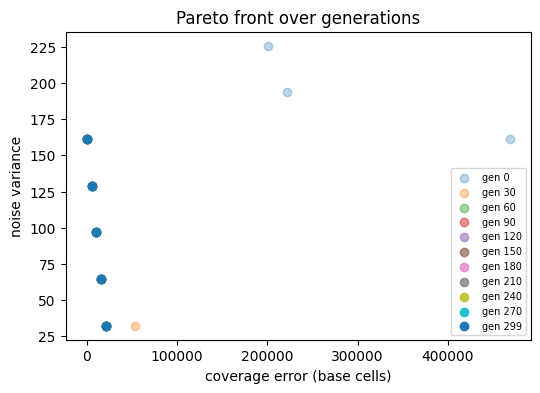

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
for g, front in enumerate(fronts):
    if g % 30 == 0 or g == len(fronts) - 1:
        pts = {(i.fitnesses["coverage"], i.fitnesses["noise"]) for i in front}
        ax.scatter(*zip(*pts), alpha=0.3 + 0.7 * g / len(fronts), label=f"gen {g}")
ax.set_xlabel("coverage error (base cells)")
ax.set_ylabel("noise variance")
ax.legend(fontsize=7)
ax.set_title("Pareto front over generations")
plt.show()

## 4. The chosen selection

Take the lowest-noise individual among those with zero coverage error.

In [7]:
best = min((i for i in fronts[-1] if i.fitnesses["coverage"] == 0),
           key=lambda i: i.fitnesses["noise"])
genome = np.array(best.genome)
problem.describe(genome)

{'selected': [(('sex*age_38_groups', ('total', 'male', '5', 'total', 'total')),
   1),
  (('sex*age_38_groups', ('total', 'male', '6', 'total', 'total')), 1),
  (('sex*age_38_groups', ('total', 'male', '7', 'total', 'total')), 1),
  (('sex*age_38_groups', ('total', 'male', '8', 'total', 'total')), 1),
  (('sex*age_38_groups', ('total', 'male', '9', 'total', 'total')), 1)],
 'coverage': 0,
 'missing': 0,
 'extra': 0,
 'noise': 161.29032135009766}

`selection_frame` turns the genome into a table keyed like a `View` frame.  Merging
against the view's `sex*age_38_groups` frame fetches the selected noisy values; for
a selection that spans several measurements, merge against each measurement's frame.

In [8]:
selected = cover.selection_frame(dhc_2020, problem, genome)
selected

,measurement,relgq,sex,age,hispanic,cenrace,sign
0,sex*age_38_groups,total,male,5,total,total,1
1,sex*age_38_groups,total,male,6,total,total,1
2,sex*age_38_groups,total,male,7,total,total,1
3,sex*age_38_groups,total,male,8,total,total,1
4,sex*age_38_groups,total,male,9,total,total,1


In [9]:
axes = list(dhc_2020.universe.axis_names)
frames = {m: view.query(m) for m in selected["measurement"].unique()}
parts = [frames[m].merge(sel, on=["measurement", *axes])
         for m, sel in selected.groupby("measurement")]
import pandas as pd
merged = pd.concat(parts, ignore_index=True)
total = sum(v * s for v, s in zip(merged["value"], merged["sign"]))
draws = sample_noisy_values(total, n=20_000, rng=np.random.default_rng(1))[0]
lo, hi = draws.credible_interval(0.95)
print(f"Male 5-9: posterior mean {draws.draws.mean():.1f}, 95% interval [{lo:.0f}, {hi:.0f}]")
print(f"sampled variance {draws.draws.var():.1f} vs predicted {best.fitnesses['noise']:.1f} (+ truncation at zero)")

Male 5-9: posterior mean 4276.0, 95% interval [4251, 4301]
sampled variance 159.5 vs predicted 161.3 (+ truncation at zero)


## Notes

- The search is over *which counts to add*, not over their values, so it needs no
  data; only the final step touches the view.
- The EA treats noise as independent across counts (true of the NMF measurements)
  and ignores the posterior's truncation at zero, so predicted and sampled
  variances agree only roughly.
- Scale: the random initialisation limits this to problems with up to a few hundred
  candidate counts.  A sparse initialisation (a few ones, rest zero) would be the
  first thing to change to extend it to all measurements.